# Лабораторная работа 6. Mini-GPT с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Собрать полный декодер-трансформер из собственных модулей и экспериментально исследовать влияние архитектурных решений: места нормализации, типа нормализации и типа FFN.

**Что нужно сдать:**
1. Реализацию GPT: RMSNorm, attention с RoPE, SwiGLU, Pre/Post-LN, weight tying, масштабированная инициализация.
2. Сверку числа параметров и FLOPs с аналитическими формулами.
3. Обученную модель и журналы loss, норм градиентов и активаций по слоям.
4. Таблицу абляций: Pre-LN/Post-LN (с warmup и без), LayerNorm/RMSNorm, GELU/SwiGLU при равном числе параметров.
5. Сгенерированные тексты и сравнение perplexity с LSTM из ЛР 3.

Модель из этой работы используется в ЛР 7, 10, 11, 13 (в них для воспроизводимости подключается эталонная реализация).

**Теория. Подсчёт параметров.** Для $L$ слоёв, ширины $d$, словаря $V$, без bias, с weight tying:
- attention: $4d^2$ (матрицы $W_Q, W_K, W_V, W_O$);
- FFN: $8d^2$ (GELU со скрытым слоем $4d$: $2 \cdot 4d^2$; SwiGLU со скрытым слоем $\tfrac{8}{3}d$: $3 \cdot \tfrac{8}{3}d^2$);
- нормализации: $2d$ на слой (RMSNorm) или $4d$ (LayerNorm с bias), плюс финальная;
- эмбеддинги: $Vd$.

Итого $N \approx 12Ld^2 + Vd$. Прямой проход стоит $\approx 2N_{\text{non-emb}} + 2LTd$ FLOPs на токен (второй член — $QK^\top$ и $PV$ при длине контекста $T$, с учётом каузальной маски в среднем вдвое меньше).


In [2]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.12.0.dev20260408+cu128, device=cuda, FAST_DEV_RUN=True


## 0. Данные

В режиме `FAST_DEV_RUN` используется Tiny Shakespeare, в полном режиме — валидационная часть TinyStories (около 22 МБ). Токенизация символьная; по желанию можно подключить BPE из ЛР 1 (дополнительное задание).

In [3]:
if FAST_DEV_RUN:
    text = load_shakespeare()
else:
    text = download("https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-valid.txt",
                    "tinystories_valid.txt").read_text(encoding="utf-8")
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; V = len(chars)
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
data = torch.tensor(encode(text)); ntr = int(0.9 * len(data)); train_data, val_data = data[:ntr], data[ntr:]
print(f"символов: {len(data):,}, |V| = {V}")

символов: 1,115,394, |V| = 65


## 1. Модули

In [ ]:
from dataclasses import dataclass, replace

@dataclass
class Config:
    vocab_size: int = V
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    norm: str = "rms"        # "rms" | "ln"
    norm_pos: str = "pre"    # "pre" | "post"
    mlp: str = "swiglu"      # "swiglu" | "gelu"
    tie_weights: bool = True

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__(); 
        self.eps = eps; 
        self.weight = nn.Parameter(torch.ones(d))
    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True).add(self.eps).rsqrt()
        return x * rms * self.weight

def make_norm(cfg): return RMSNorm(cfg.n_embd) if cfg.norm == "rms" else nn.LayerNorm(cfg.n_embd)

def rope_cache(T, d_head, base=10000.0):
    inv = base ** (-torch.arange(0, d_head, 2).float() / d_head)
    ang = torch.outer(torch.arange(T).float(), inv)
    return ang.cos(), ang.sin()

def apply_rope(x, cos, sin):
    T = x.shape[-2]
    c = cos[:T].unsqueeze(0).unsqueeze(0)
    s = sin[:T].unsqueeze(0).unsqueeze(0)

    x1, x2 = x[..., 0::2], x[..., 1::2]

    y1 = x1 * c - x2 * s
    y2 = x1 * s + x2 * c

    return torch.stack([y1, y2], dim=-1).flatten(-2)

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.h, self.dh = cfg.n_head, cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
    def forward(self, x, cos, sin):
        B, T, C = x.shape
        # (q, k, v → (B, H, T, dh); RoPE для q и k; собственная или F.scaled_dot_product_attention с is_causal)
        qkv = self.qkv(x)
        q, k, v = qkv.split(C, dim=-1)

        q = q.view(B, T, self.h, self.dh).transpose(1, 2)
        k = k.view(B, T, self.h, self.dh).transpose(1, 2)
        v = v.view(B, T, self.h, self.dh).transpose(1, 2)

        q = apply_rope(q, cos, sin)
        k = apply_rope(k, cos, sin)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        return self.proj(y)

class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__(); d = cfg.n_embd; self.kind = cfg.mlp
        if cfg.mlp == "swiglu":
            hidden = int(8 * d / 3)
            self.w1, self.w3, self.w2 = nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False), nn.Linear(hidden, d, bias=False)
        else:
            self.w1, self.w2 = nn.Linear(d, 4 * d, bias=False), nn.Linear(4 * d, d, bias=False)
    def forward(self, x):
        if self.kind == "swiglu":
            return self.w2(F.silu(self.w1(x)) * self.w3(x))
        return self.w2(F.gelu(self.w1(x)))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__(); self.pos = cfg.norm_pos
        self.n1, self.attn, self.n2, self.mlp = make_norm(cfg), CausalSelfAttention(cfg), make_norm(cfg), MLP(cfg)
    def forward(self, x, cos, sin):
        # (Pre-LN: x + f(norm(x)); Post-LN: norm(x + f(x)))
        if self.pos == "pre":
            x = x + self.attn(self.n1(x), cos, sin)
            x = x + self.mlp(self.n2(x))
        else:  # post
            x = self.n1(x + self.attn(x, cos, sin))
            x = self.n2(x + self.mlp(x))
        return x

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__(); self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm_f = make_norm(cfg) if cfg.norm_pos == "pre" else nn.Identity()
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        if cfg.tie_weights: self.head.weight = self.wte.weight
        cos, sin = rope_cache(cfg.block_size, cfg.n_embd // cfg.n_head)
        self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
        # (N(0, 0.02) для всех Linear/Embedding, выходные проекции proj и w2 — 0.02/sqrt(2L))
        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("w2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None: nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
                
    def forward(self, idx, targets=None, return_hidden=False):
        x = self.wte(idx); hidden = [x]
        for b in self.blocks:
            x = b(x, self.cos, self.sin); hidden.append(x)
        logits = self.head(self.norm_f(x))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return (logits, loss, hidden) if return_hidden else (logits, loss)
    @torch.no_grad()
    def generate(self, idx, n, temperature=1.0, top_k=None):
        for _ in range(n):
            logits = self(idx[:, -self.cfg.block_size:])[0][:, -1] / temperature
            if top_k: logits[logits < logits.topk(top_k).values[:, -1:]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(logits.softmax(-1), 1)], 1)
        return idx

## 2. Число параметров и FLOPs

Реализуйте аналитические формулы и сверьте их с фактическим числом параметров для нескольких конфигураций. Измерьте FLOPs прямого прохода профайлером `torch.utils.flop_counter.FlopCounterMode` и сравните с формулой $2N_{\text{non-emb}} + 2LTd$ на токен (плюс $2Vd$ на выходную голову).


In [ ]:
def analytic_params(cfg):
    d, V, L = cfg.n_embd, cfg.vocab_size, cfg.n_layer
    params = V * d

    if not cfg.tie_weights: params += V * d

    attn = 4 * d * d
    
    if cfg.mlp == "swiglu":
        h = int(8 * d / 3); 
        ffn = 3 * d * h
    else:
        ffn = 2 * d * 4 * d

    norm_per = d if cfg.norm == "rms" else 2 * d

    params += L * (attn + ffn + 2 * norm_per)

    if cfg.norm_pos == "pre": params += norm_per

    return params

def analytic_forward_flops(cfg, T):
    """FLOPs прямого прохода на всю последовательность длины T (умножение+сложение = 2 FLOP)."""
    d, L, V = cfg.n_embd, cfg.n_layer, cfg.vocab_size

    if cfg.mlp == "swiglu":
        h = int(8 * d / 3); 
        ffn = 6 * d * h
    else:
        ffn = 16 * d * d

    attn_proj = 8 * d * d
    per_layer = (attn_proj + ffn) * T + 2 * T * T * d
    return L * per_layer + 2 * T * V * d

from torch.utils.flop_counter import FlopCounterMode
for cfg in [Config(), 
            Config(n_layer=6, n_embd=192, n_head=6, mlp="gelu"), 
            Config(norm="ln", tie_weights=False)]:
    m = GPT(cfg); x = torch.randint(V, (1, cfg.block_size))
    fc = FlopCounterMode(display=False)
    with fc, torch.no_grad(): m(x)
    print(f"L={cfg.n_layer} d={cfg.n_embd} {cfg.mlp:6s} {cfg.norm}: params={sum(p.numel() for p in m.parameters()):,} "
          f"(формула {analytic_params(cfg):,}); FLOPs={fc.get_total_flops():.3e} (формула {analytic_forward_flops(cfg, cfg.block_size):.3e})")
    assert sum(p.numel() for p in m.parameters()) == analytic_params(cfg)

L=4 d=128 swiglu rms: params=795,392 (формула 795,392); FLOPs=2.033e+08 (формула 2.201e+08)
L=6 d=192 gelu   rms: params=2,669,184 (формула 2,669,184); FLOPs=6.827e+08 (формула 7.204e+08)
L=4 d=128 swiglu ln: params=804,864 (формула 804,864); FLOPs=2.033e+08 (формула 2.201e+08)


## 3. Обучение с журналом диагностик

Логируйте каждые `LOG_EVERY` шагов:
- loss на обучении и валидации;
- норму градиента по каждому блоку;
- RMS активаций residual stream после каждого блока.

In [ ]:
def get_batch(d, T, B):
    ix = torch.randint(len(d) - T - 1, (B,))
    return torch.stack([d[i:i + T] for i in ix]).to(DEVICE), torch.stack([d[i + 1:i + T + 1] for i in ix]).to(DEVICE)

@torch.no_grad()
def eval_loss(model, d, iters=20, B=32):
    model.eval(); l = np.mean([model(*get_batch(d, model.cfg.block_size, B))[1].item() for _ in range(iters)]); model.train(); return l

def train(cfg, steps, lr=3e-3, warmup=100, B=32, log_every=50, seed=SEED):
    set_seed(seed); 
    model = GPT(cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    # (линейный warmup + косинусное затухание (LambdaLR); clip_grad_norm_(1.0); журнал диагностик)
    def lr_lambda(step):
        if step < warmup:
            return step / max(1, warmup)
        progress = (step - warmup) / max(1, steps - warmup)
        return 0.5 * (1.0 + math.cos(math.pi * progress))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    log = {"step": [], "train": [], "val": [], "grad": [], "act": []}
    for step in range(steps):
        x, y = get_batch(train_data, cfg.block_size, B)
        logits, loss = model(x, y)
        opt.zero_grad()
        loss.backward()

        gnorms = []
        for b in model.blocks:
            g = b.attn.proj.weight.grad
            gnorms.append(g.norm().item() if g is not None else 0.0)
            
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); 
        sched.step()

        if step % log_every == 0 or step == steps - 1:
            model.eval()
            with torch.no_grad():
                _, vl, hidden = model(*get_batch(val_data, cfg.block_size, B), return_hidden=True)
                act_rms = [h.pow(2).mean().sqrt().item() for h in hidden[1:]]
            model.train()
            log["step"].append(step); 
            log["train"].append(loss.item()); 
            log["val"].append(vl.item())
            log["grad"].append(gnorms); 
            log["act"].append(act_rms)
            print(f"step {step:4d} | lr {sched.get_last_lr()[0]:.2e} | train {loss.item():.3f} | val {vl.item():.3f}")
    return model, log

STEPS = 300 if FAST_DEV_RUN else 5000
base_cfg = Config(block_size=128 if FAST_DEV_RUN else 256, n_layer=4 if FAST_DEV_RUN else 6,
                  n_embd=128 if FAST_DEV_RUN else 384, n_head=4 if FAST_DEV_RUN else 6)
t0 = time.time(); model, log = train(base_cfg, STEPS)
print(f"{time.time() - t0:.0f} c; параметров {sum(p.numel() for p in model.parameters()):,}; val loss {log['val'][-1]:.3f}")
torch.save({"cfg": base_cfg.__dict__, "state": model.state_dict(), "chars": chars}, ARTIFACTS / "lab06_gpt.pt")

step    0 | lr 3.00e-05 | train 4.263 | val 4.253
step   50 | lr 1.53e-03 | train 2.592 | val 2.554
step  100 | lr 3.00e-03 | train 2.121 | val 2.167
step  150 | lr 2.54e-03 | train 1.888 | val 1.985
step  200 | lr 1.48e-03 | train 1.789 | val 1.899
step  250 | lr 4.23e-04 | train 1.673 | val 1.853
step  299 | lr 0.00e+00 | train 1.672 | val 1.807
4 c; параметров 795,392; val loss 1.807


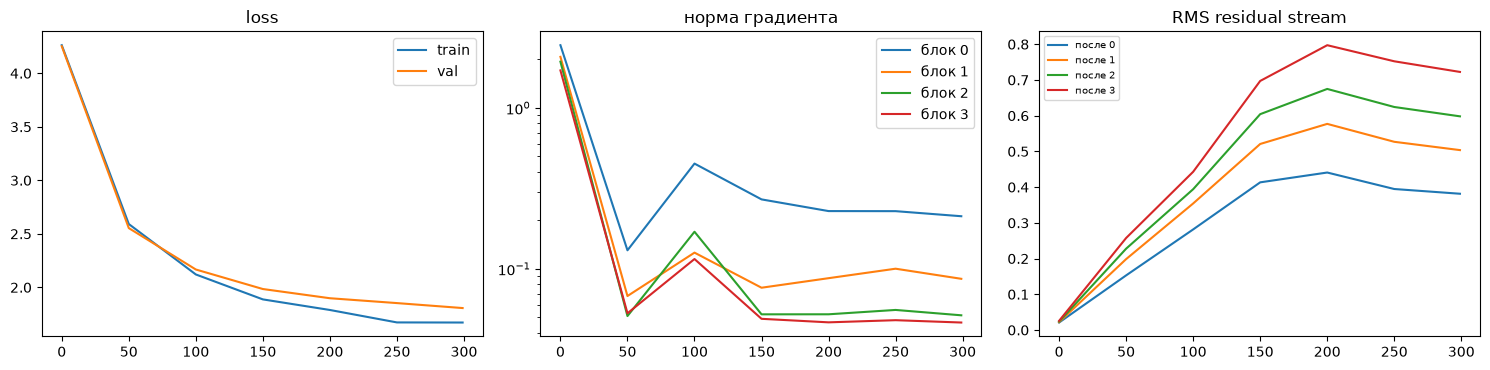

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(log["step"], log["train"], label="train"); ax[0].plot(log["step"], log["val"], label="val"); ax[0].legend(); ax[0].set_title("loss")
g = np.array(log["grad"]); [ax[1].plot(log["step"], g[:, i], label=f"блок {i}") for i in range(g.shape[1])]; ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("норма градиента")
a = np.array(log["act"]); [ax[2].plot(log["step"], a[:, i], label=f"после {i}") for i in range(a.shape[1])]; ax[2].legend(fontsize=7); ax[2].set_title("RMS residual stream")
plt.tight_layout(); plt.show()

## 4. Абляции

Обучите при одинаковом бюджете шагов:

| Вариант | Изменение относительно базового |
|---|---|
| base | Pre-RMSNorm, SwiGLU, warmup (10% шагов) |
| post-ln | Post-norm, warmup |
| post-ln, без warmup | Post-norm, warmup 0 |
| pre-ln, без warmup | Pre-norm, warmup 0 |
| layernorm | LayerNorm вместо RMSNorm |
| gelu | GELU-FFN (4d) вместо SwiGLU (8d/3) |

Используйте два значения learning rate (3e-3 и 1e-2; в `FAST_DEV_RUN` только 1e-2), чтобы выявить неустойчивость. Сравните итоговый val loss, долю «взорвавшихся» запусков и нормы градиентов по слоям в начале обучения.

step    0 | lr 3.33e-04 | train 4.238 | val 4.221
step    1 | lr 6.67e-04 | train 4.233 | val 3.969
step    2 | lr 1.00e-03 | train 3.977 | val 3.813
step    3 | lr 1.33e-03 | train 3.753 | val 3.667
step    4 | lr 1.67e-03 | train 3.663 | val 3.672
step    5 | lr 2.00e-03 | train 3.598 | val 3.596
step    6 | lr 2.33e-03 | train 3.488 | val 3.455
step    7 | lr 2.67e-03 | train 3.478 | val 3.349
step    8 | lr 3.00e-03 | train 3.333 | val 3.462
step    9 | lr 3.33e-03 | train 3.298 | val 3.275
step   10 | lr 3.67e-03 | train 3.399 | val 3.415
step   11 | lr 4.00e-03 | train 3.412 | val 3.424
step   12 | lr 4.33e-03 | train 3.249 | val 3.268
step   13 | lr 4.67e-03 | train 3.284 | val 3.216
step   14 | lr 5.00e-03 | train 3.126 | val 3.328
step   15 | lr 5.33e-03 | train 3.231 | val 3.252
step   16 | lr 5.67e-03 | train 3.241 | val 3.109
step   17 | lr 6.00e-03 | train 3.186 | val 3.277
step   18 | lr 6.33e-03 | train 3.139 | val 3.185
step   19 | lr 6.67e-03 | train 3.226 | val 3.147


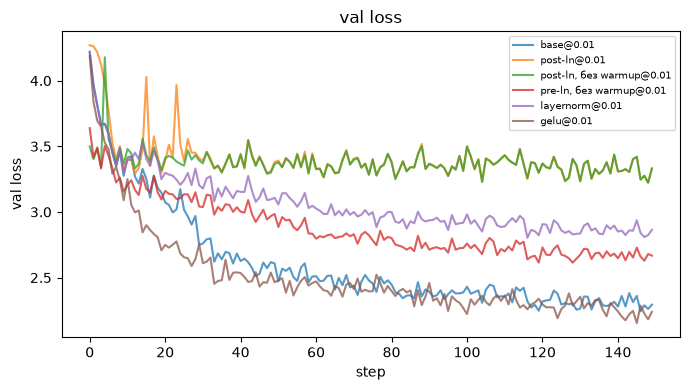

In [ ]:
ABL_STEPS = 150 if FAST_DEV_RUN else 3000
ABL_LRS = (1e-2,) if FAST_DEV_RUN else (3e-3, 1e-2)
abl_cfg = replace(base_cfg, block_size=64) if FAST_DEV_RUN else base_cfg
variants = {
    "base": (abl_cfg, 30), "post-ln": (replace(abl_cfg, norm_pos="post"), 30),
    "post-ln, без warmup": (replace(abl_cfg, norm_pos="post"), 0), "pre-ln, без warmup": (abl_cfg, 0),
    "layernorm": (replace(abl_cfg, norm="ln"), 30), "gelu": (replace(abl_cfg, mlp="gelu"), 30),
}
# (обучите все варианты при lr из {3e-3, 1e-2}, соберите таблицу и графики норм градиентов на первых шагах)
abl_results = {}
for vname, (vcfg, wu) in variants.items():
    for lr in ABL_LRS:
        key = f"{vname}@{lr}"
        m, lg = train(vcfg, ABL_STEPS, lr=lr, warmup=wu, B=16, log_every=1)
        vl = lg["val"][-1]
        g0 = np.array(lg["grad"][0]) if lg["grad"] else np.array([])
        finite = math.isfinite(vl)
        exploded = (not finite) or (finite and vl > 2 * math.log(vcfg.vocab_size))
        abl_results[key] = {"val": vl, "g0": g0, "log": lg, "exploded": exploded}

print()
print(f"{'':<24s} {'LR':>8s} {'Val loss':>10s} {'Grad@0':>10s} {'Статус':>10s}")
print("-" * 68)
for k, r in abl_results.items():
    vname, lr_s = k.rsplit("@", 1)
    status = "OK" if math.isfinite(r["val"]) and not r["exploded"] else "ВЗРЫВ"
    gm = r["g0"].mean() if r["g0"].size else float("nan")
    print(f"{vname:<24s} {lr_s:>8s} {r['val']:>10.3f} {gm:>10.2e} {status:>10s}")
n_expl = sum(r["exploded"] for r in abl_results.values())
print(f"\nВзорвалось: {n_expl}/{len(abl_results)} ({100*n_expl/len(abl_results):.0f}%)")

fig, ax = plt.subplots(1, 1, figsize=(7, 4))
for k, r in abl_results.items():
    ax.plot(r["log"]["step"], r["log"]["val"], label=k, alpha=0.75)

ax.set_xlabel("step")
ax.set_ylabel("val loss")
ax.set_title("val loss")
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


## 5. Генерация и сравнение с LSTM

Сгенерируйте тексты при разных температурах и top-k. Посчитайте perplexity и bits-per-character на валидации и сравните с LSTM из ЛР 3 (для Shakespeare при коротком обучении LSTM давала около 2.5 бит/символ).

In [11]:
val_ce = eval_loss(model, val_data, iters=50)
print(f"GPT: CE={val_ce:.3f} нат, perplexity={math.exp(val_ce):.2f}, bpc={val_ce / math.log(2):.3f}")
for t, k in [(0.5, None), (1.0, None), (1.0, 10)]:
    out = model.generate(torch.tensor([encode("ROMEO:" if FAST_DEV_RUN else "Once upon a time")], device=DEVICE), 300, t, k)
    print(f"\n--- T={t}, top_k={k}\n{decode(out[0].tolist())}")

GPT: CE=1.810 нат, perplexity=6.11, bpc=2.612

--- T=0.5, top_k=None
ROMEO:
The sea not the now of make distred thee,
And the better of him that will stood thought,
The leave could so devil the good a more.

First Sence with help and we me may and the hand
The will were him as the cannot words thee?

First the king the word heart the cannot in thee,
The will her son and sa

--- T=1.0, top_k=None
ROMEO:
Sio be't lord, you dishierpentient,
I hast I heart Hantible the midis again;
Bee surfore instil.

ISABELLO:
Hers as God:
Kecry Mease be on my farirstatess: take you, make as
Besents be sit unpinting. Ans from do Richubler theon,
Comean can syvon you trien, this sto;
As speak are.

RUTUS:
Serves suc

--- T=1.0, top_k=10
ROMEO:
Nor you, me, what bodam!

A benour was brither; I thougn touch he,
That him me bick a son may action of that
And you do muphtrock fleed on merier,
Whose one you worsholess; I truntes offer'd
Mure to the worsh thou say and thus wrongs of.

PRAM:
You convery, not shal

## Вопросы

1. Почему Post-LN требует warmup, а Pre-LN обучается и без него? Свяжите ответ с нормами градиентов по слоям при инициализации (Xiong et al., 2020).
2. Зачем выходные проекции инициализируются с множителем \(1/\sqrt{2L}\)? Что происходит с дисперсией residual stream без этого множителя?
3. Почему у SwiGLU скрытый размер \(\tfrac{8}{3}d\)? Какое свойство сравнения это обеспечивает?
4. Что даёт weight tying и почему оно естественно для языковой модели?
5. Какая доля FLOPs приходится на attention при \(T = 128\) и при \(T = 8192\) для вашей конфигурации? При каком \(T\) attention начинает доминировать?

Выводы: обучили языковую модель GPT с нуля. Проверили, сколько у неё параметров и FLOPS, и сверили с формулами. Сравнили разные варианты модели. Сгенерировали тексты и посчитали perplexity